# Financial Sentiment Analysis: Fine-Tuned FinBERT vs LLMs

**Question:** for classifying financial news sentiment, does a small domain-specific model fine-tuned on labelled data beat a general-purpose LLM prompted zero-/few-shot? And at what cost?

**Models compared** (same held-out test set, same metric):
1. **TF-IDF + Logistic Regression**: classical baseline
2. **BERT-base**: general-domain transformer, fine-tuned
3. **FinBERT**: transformer pre-trained on financial text, fine-tuned
4. **Qwen2.5-1.5B-Instruct, zero-shot**: open-source LLM, no training
5. **Qwen2.5-1.5B-Instruct, few-shot**: same LLM with 6 labelled examples in the prompt

**Data:** Financial PhraseBank (Malo et al., 2014): ~4,800 sentences from financial news, labelled by finance-literate annotators.

**How to run:** In Colab choose `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. It takes about 15–20 minutes and is free.

In [25]:
!pip -q install "transformers>=4.44" "datasets<4.0" accelerate gradio scikit-learn

In [26]:
import io, os, re, time, random, zipfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED)
LABELS = ["negative", "neutral", "positive"]
OUT = "results"; os.makedirs(OUT, exist_ok=True)

## 1. Load the data
We use the **50% agreement** subset (all ~4,800 sentences where at least half the annotators agreed). Duplicate sentences are removed so that no sentence can end up in both train and test.

In [27]:
def load_phrasebank(subset="Sentences_50Agree"):
    try:
        from datasets import load_dataset
        ds = load_dataset("takala/financial_phrasebank", subset.lower(), trust_remote_code=True)["train"]
        names = ds.features["label"].names
        df = ds.to_pandas().rename(columns={"sentence": "text"})
        df["label"] = df["label"].map(lambda i: names[i])
    except Exception as e:
        print("load_dataset failed, downloading the raw zip instead:", repr(e)[:200])
        url = "https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip"
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
        name = [n for n in z.namelist() if n.endswith(subset + ".txt")][0]
        lines = z.read(name).decode("latin-1").splitlines()
        df = pd.DataFrame([l.rsplit("@", 1) for l in lines if "@" in l], columns=["text", "label"])
    df["text"] = df["text"].str.strip(); df["label"] = df["label"].str.strip()
    return df.drop_duplicates("text").reset_index(drop=True)

df = load_phrasebank()
print(len(df), "sentences")
print(df.label.value_counts(normalize=True).round(3))
df.sample(5, random_state=SEED)

load_dataset failed, downloading the raw zip instead: HfUriError("Invalid HF URI 'hf://datasets/financial_phrasebank@main/data/FinancialPhraseBank-v1.0.zip'. Repository id must be 'namespace/name', got 'financial_phrasebank'.")
4838 sentences
label
neutral     0.594
positive    0.282
negative    0.125
Name: proportion, dtype: float64


,text,label
3197,"The Company serves approximately 3,000 custome...",neutral
2526,"On Dec. 1 , Grimaldi acquired 1.5 million shar...",neutral
4099,The extracted filtrates are very high in clari...,neutral
1926,The vessels also have to be environmentally fr...,neutral
1536,"In recent months , Capman has taken significan...",positive


### Train / validation / test split (70 / 15 / 15, stratified)
The **test set is never touched** until final evaluation. Model choices (epochs, regularisation) are made on the **validation** set only.

The classes are imbalanced (neutral is about 60%), so the headline metric is **macro-F1**, which weights each class equally. A model that always predicts "neutral" would score about 60% accuracy but only about 0.25 macro-F1.

In [28]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

results, preds = [], {}
def record(name, y_pred, secs, params_m, notes=""):
    y_true = test_df.label.tolist()
    results.append(dict(model=name,
                        macro_f1=round(f1_score(y_true, y_pred, average="macro"), 4),
                        accuracy=round(accuracy_score(y_true, y_pred), 4),
                        ms_per_sentence=round(1000 * secs / len(y_true), 3),
                        params_millions=params_m, notes=notes))
    preds[name] = list(y_pred)
    print(f"{name}: macro-F1 {results[-1]['macro_f1']:.3f} | acc {results[-1]['accuracy']:.3f} | {results[-1]['ms_per_sentence']} ms/sentence")

train 3386 | val 726 | test 726


## 2. Baseline: TF-IDF + Logistic Regression
The regularisation strength `C` is tuned on the validation set.

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr, Xva = vec.fit_transform(train_df.text), vec.transform(val_df.text)
best_C = max([0.5, 1, 2, 4, 8, 16], key=lambda C: f1_score(
    val_df.label, LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Xtr, train_df.label).predict(Xva), average="macro"))
logreg = LogisticRegression(C=best_C, max_iter=3000, class_weight="balanced").fit(Xtr, train_df.label)

t = time.perf_counter()
p = logreg.predict(vec.transform(test_df.text))
record("TF-IDF + LogReg", p, time.perf_counter() - t, round(logreg.coef_.size / 1e6, 3), f"C={best_C}")

TF-IDF + LogReg: macro-F1 0.750 | acc 0.786 | 0.249 ms/sentence


## 3. Fine-tune BERT and FinBERT
**Why `yiyanghkust/finbert-pretrain` and not the popular `ProsusAI/finbert`?** ProsusAI/finbert was **already fine-tuned on Financial PhraseBank**, so testing it here would leak test data into training and inflate the score. `finbert-pretrain` is pre-trained on financial text (reports, filings, analyst notes) but has **never seen sentiment labels**. That makes this a fair test of whether domain pre-training helps.

BERT-base (same architecture, general-domain text) isolates the effect of the **financial pre-training**.

In [30]:
import torch, inspect
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
lab2id = {l: i for i, l in enumerate(LABELS)}

def finetune(model_name, out_dir, epochs=4, lr=2e-5):
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=lab2id, ignore_mismatched_sizes=True)
    def enc(d):
        ds = Dataset.from_dict({"text": d.text.tolist(), "labels": d.label.map(lab2id).tolist()})
        return ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])
    def metrics(p):
        y = p.predictions.argmax(-1)
        return {"macro_f1": f1_score(p.label_ids, y, average="macro"), "accuracy": accuracy_score(p.label_ids, y)}
    kw = dict(output_dir=out_dir, save_strategy="epoch", learning_rate=lr,
              per_device_train_batch_size=32, per_device_eval_batch_size=64, num_train_epochs=epochs,
              weight_decay=0.01, load_best_model_at_end=True, metric_for_best_model="macro_f1",
              save_total_limit=1, fp16=(DEVICE == "cuda"), report_to="none", seed=SEED, logging_steps=50,
              warmup_steps=int(0.1 * epochs * np.ceil(len(train_df) / 32)))
    params = inspect.signature(TrainingArguments.__init__).parameters
    kw["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = "epoch"
    trainer = Trainer(model=model, args=TrainingArguments(**kw), train_dataset=enc(train_df),
                      eval_dataset=enc(val_df), data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()
    return trainer.model, tok

@torch.no_grad()
def predict_clf(model, tok, texts, bs=64):
    model.eval(); out = []
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for i in range(0, len(texts), bs):
        b = tok(texts[i:i + bs], truncation=True, max_length=128, padding=True, return_tensors="pt").to(model.device)
        out.append(model(**b).logits.float().cpu())
    if DEVICE == "cuda": torch.cuda.synchronize()
    probs = torch.cat(out).softmax(-1).numpy()
    return [LABELS[i] for i in probs.argmax(1)], probs, time.perf_counter() - t

n_params = lambda m: round(sum(p.numel() for p in m.parameters()) / 1e6, 1)

Device: cuda


In [31]:
bert, bert_tok = finetune("bert-base-uncased", "ckpt_bert")
p, _, secs = predict_clf(bert, bert_tok, test_df.text.tolist())
record("BERT-base (fine-tuned)", p, secs, n_params(bert))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/3386 [00:00<?, ? examples/s]

Map:   0%|          | 0/726 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.703950,0.502267,0.792981,0.822314
2,0.352230,0.401154,0.830909,0.848485
3,0.225935,0.378123,0.844751,0.863636
4,0.161161,0.385469,0.851905,0.869146


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT-base (fine-tuned): macro-F1 0.862 | acc 0.877 | 1.322 ms/sentence


In [36]:
import inspect
from transformers import BertForSequenceClassification
try:
    from transformers import BertTokenizerFast as BertTok
except ImportError:
    from transformers import BertTokenizer as BertTok

NAME = "yiyanghkust/finbert-pretrain"
finbert_tok = BertTok.from_pretrained(NAME, do_lower_case=True)
print("Tokenizer OK:", finbert_tok("Operating profit rose")["input_ids"])

model = BertForSequenceClassification.from_pretrained(
    NAME, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=lab2id, ignore_mismatched_sizes=True)
print("Model OK")

def enc(d):
    ds = Dataset.from_dict({"text": d.text.tolist(), "labels": d.label.map(lab2id).tolist()})
    return ds.map(lambda b: finbert_tok(b["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])

def metrics(p):
    y = p.predictions.argmax(-1)
    return {"macro_f1": f1_score(p.label_ids, y, average="macro"), "accuracy": accuracy_score(p.label_ids, y)}

kw = dict(output_dir="ckpt_finbert", save_strategy="epoch", learning_rate=2e-5,
          per_device_train_batch_size=32, per_device_eval_batch_size=64, num_train_epochs=4,
          weight_decay=0.01, load_best_model_at_end=True, metric_for_best_model="macro_f1",
          save_total_limit=1, fp16=(DEVICE == "cuda"), report_to="none", seed=SEED, logging_steps=50,
          warmup_steps=int(0.1 * 4 * np.ceil(len(train_df) / 32)))
params = inspect.signature(TrainingArguments.__init__).parameters
kw["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = "epoch"

trainer = Trainer(model=model, args=TrainingArguments(**kw), train_dataset=enc(train_df), eval_dataset=enc(val_df),
                  data_collator=DataCollatorWithPadding(finbert_tok), compute_metrics=metrics)
trainer.train()
finbert = trainer.model

p, _, secs = predict_clf(finbert, finbert_tok, test_df.text.tolist())
record("FinBERT (fine-tuned)", p, secs, n_params(finbert))

Tokenizer OK: [3, 51, 358, 1851, 4]


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  442MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

Model OK


... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

FinBERT (fine-tuned): macro-F1 0.851 | acc 0.864 | 1.002 ms/sentence


## 4. LLM: zero-shot and few-shot prompting
We use **Qwen2.5-1.5B-Instruct**, an open-source instruction-tuned LLM. It runs free on the Colab GPU, needs no API key, and is about **14× larger** than BERT. Decoding is greedy (deterministic). If the LLM gives an answer that doesn't parse, it falls back to "neutral" and the notebook counts how often that happens.

Few-shot examples are drawn **only from the training set**: 2 per class.

In [37]:
from transformers import AutoModelForCausalLM
LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME, padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE)

SYSTEM = ("You are a financial analyst. Classify the sentiment of a financial news sentence from the point of view "
          "of an investor in the company mentioned. Answer with exactly one word: positive, negative, or neutral.")

def build_prompt(text, shots):
    msgs = [{"role": "system", "content": SYSTEM}]
    for s, l in shots:
        msgs += [{"role": "user", "content": f"Sentence: {s}"}, {"role": "assistant", "content": l}]
    msgs.append({"role": "user", "content": f"Sentence: {text}"})
    return llm_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def parse(o):
    o = o.strip().lower()
    for l in LABELS:
        if o.startswith(l): return l
    for l in LABELS:
        if l in o: return l
    return None

@torch.no_grad()
def predict_llm(texts, shots, bs=32):
    out, bad = [], 0
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for i in range(0, len(texts), bs):
        enc = llm_tok([build_prompt(x, shots) for x in texts[i:i + bs]], return_tensors="pt", padding=True).to(DEVICE)
        gen = llm.generate(**enc, max_new_tokens=3, do_sample=False, pad_token_id=llm_tok.pad_token_id or llm_tok.eos_token_id)
        for o in llm_tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True):
            lab = parse(o)
            bad += lab is None
            out.append(lab or "neutral")
    if DEVICE == "cuda": torch.cuda.synchronize()
    return out, time.perf_counter() - t, bad

shots = [(r.text, r.label) for l in LABELS for r in train_df[train_df.label == l].sample(2, random_state=SEED).itertuples()]
random.Random(SEED).shuffle(shots)
llm_params = n_params(llm)

p, secs, bad = predict_llm(test_df.text.tolist(), shots=[])
record("Qwen2.5-1.5B zero-shot", p, secs, llm_params, f"{bad} unparseable")
p, secs, bad = predict_llm(test_df.text.tolist(), shots=shots)
record("Qwen2.5-1.5B few-shot (6)", p, secs, llm_params, f"{bad} unparseable")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5-1.5B zero-shot: macro-F1 0.778 | acc 0.766 | 18.813 ms/sentence
Qwen2.5-1.5B few-shot (6): macro-F1 0.792 | acc 0.791 | 52.37 ms/sentence


## 5. Results

                       model  macro_f1  accuracy  ms_per_sentence  params_millions          notes
0     BERT-base (fine-tuned)    0.8618    0.8774            1.322          109.500               
1       FinBERT (fine-tuned)    0.8505    0.8636            1.002          109.800               
2  Qwen2.5-1.5B few-shot (6)    0.7918    0.7906           52.370         1543.700  0 unparseable
3     Qwen2.5-1.5B zero-shot    0.7784    0.7658           18.813         1543.700  0 unparseable
4            TF-IDF + LogReg    0.7500    0.7865            0.249            0.033            C=4


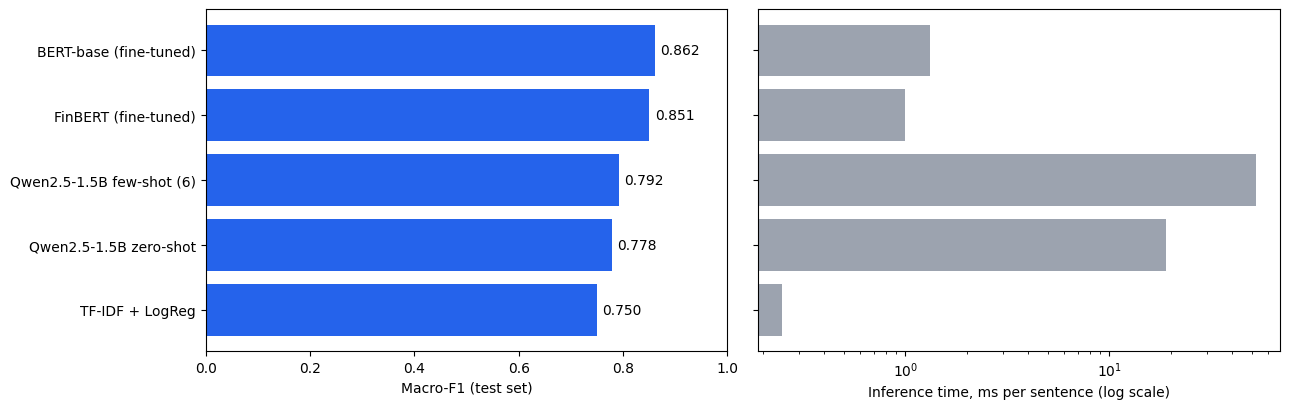

Best model: BERT-base (fine-tuned)

              precision    recall  f1-score   support

    negative      0.857     0.857     0.857        91
     neutral      0.896     0.919     0.907       431
    positive      0.845     0.799     0.821       204

    accuracy                          0.877       726
   macro avg      0.866     0.858     0.862       726
weighted avg      0.877     0.877     0.877       726



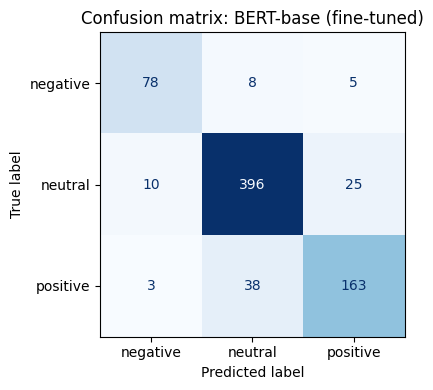

In [38]:
res = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
res.to_csv(f"{OUT}/results.csv", index=False)
display(res) if "display" in globals() else print(res.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
order = res.sort_values("macro_f1")
ax[0].barh(order.model, order.macro_f1, color="#2563eb"); ax[0].set_xlabel("Macro-F1 (test set)"); ax[0].set_xlim(0, 1)
for y, v in enumerate(order.macro_f1): ax[0].text(v + 0.01, y, f"{v:.3f}", va="center")
ax[1].barh(order.model, order.ms_per_sentence, color="#9ca3af"); ax[1].set_xscale("log"); ax[1].set_xlabel("Inference time, ms per sentence (log scale)")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(f"{OUT}/model_comparison.png", dpi=150); plt.show()

best = res.model.iloc[0]
print(f"Best model: {best}\n")
print(classification_report(test_df.label, preds[best], labels=LABELS, digits=3))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(test_df.label, preds[best], labels=LABELS), display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {best}"); plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=150); plt.show()

## 6. Error analysis: where do models fail?
We tag each test sentence with simple linguistic patterns and compare each model's **error rate** on them. A rate above the "all sentences" row means that pattern is hard for the model.

In [39]:
PATTERNS = {
    "negation": r"\b(?:not|no|never|without|neither|nor|cannot)\b|n't\b",
    "hedging / forward-looking": r"\b(?:may|might|could|expect\w*|likely|estimat\w*|forecast\w*|anticipat\w*|guidance|outlook)\b",
    "contains numbers": r"\d",
    "direction words": r"\b(?:increas\w*|decreas\w*|rose|fell|grew|declin\w*|up|down|rise|drop\w*)\b",
}
tags = pd.DataFrame({k: test_df.text.str.contains(v, case=False, regex=True) for k, v in PATTERNS.items()})
rows = []
for tag in ["all sentences"] + list(PATTERNS):
    mask = pd.Series(True, index=test_df.index) if tag == "all sentences" else tags[tag]
    row = {"pattern": tag, "n": int(mask.sum())}
    for m, p in preds.items():
        row[m] = round(float((pd.Series(p)[mask] != test_df.label[mask]).mean()), 3) if mask.sum() else np.nan
    rows.append(row)
err_table = pd.DataFrame(rows); err_table.to_csv(f"{OUT}/error_rates_by_pattern.csv", index=False)
display(err_table) if "display" in globals() else print(err_table.to_string())

wrong = test_df.assign(pred=preds[best])
wrong = wrong[wrong.pred != wrong.label]
print(f"\n{len(wrong)} sentences misclassified by {best}. Examples:")
for r in wrong.sample(min(10, len(wrong)), random_state=SEED).itertuples():
    print(f"  true={r.label:<8} pred={r.pred:<8} | {r.text[:140]}")

                     pattern    n  TF-IDF + LogReg  BERT-base (fine-tuned)  FinBERT (fine-tuned)  Qwen2.5-1.5B zero-shot  Qwen2.5-1.5B few-shot (6)
0              all sentences  726            0.213                   0.123                 0.136                   0.234                      0.209
1                   negation   25            0.160                   0.000                 0.040                   0.200                      0.240
2  hedging / forward-looking   44            0.318                   0.182                 0.159                   0.205                      0.205
3           contains numbers  394            0.178                   0.099                 0.109                   0.241                      0.188
4            direction words  115            0.122                   0.061                 0.043                   0.078                      0.078

89 sentences misclassified by BERT-base (fine-tuned). Examples:
  true=neutral  pred=negative | Garmin fell 4.5

## 7. Interactive demo (Gradio)
Running this cell gives you a public link that stays live while the notebook is open. To host it permanently for free, use **Hugging Face Spaces** (see the README).

In [40]:
import gradio as gr
def classify(text):
    _, probs, _ = predict_clf(finbert, finbert_tok, [text])
    return {l: float(p) for l, p in zip(LABELS, probs[0])}

gr.Interface(fn=classify,
             inputs=gr.Textbox(lines=3, label="Financial news sentence"),
             outputs=gr.Label(num_top_classes=3, label="Sentiment"),
             title="Financial News Sentiment: Fine-tuned FinBERT",
             examples=["Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in the corresponding period in 2007.",
                       "The company said it expects net sales to decline in the second half of the year.",
                       "The annual general meeting will be held in Helsinki on 25 March."]).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4e3a2a882bdc320c03.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. Write your resume numbers down
After **Run all**, copy these into your CV bullets and README. They're real results, so you can defend every one.

In [41]:
r = res.set_index("model")
fb, bb, lr = r.loc["FinBERT (fine-tuned)"], r.loc["BERT-base (fine-tuned)"], r.loc["TF-IDF + LogReg"]
zs, fs = r.loc["Qwen2.5-1.5B zero-shot"], r.loc["Qwen2.5-1.5B few-shot (6)"]
print(f"Dataset: {len(df)} sentences | test set: {len(test_df)}")
print(f"FinBERT macro-F1 {fb.macro_f1:.3f} vs BERT {bb.macro_f1:.3f} vs TF-IDF {lr.macro_f1:.3f}")
print(f"LLM zero-shot {zs.macro_f1:.3f}, few-shot {fs.macro_f1:.3f}")
print(f"FinBERT is {zs.ms_per_sentence / fb.ms_per_sentence:.0f}x faster than the LLM and {zs.params_millions / fb.params_millions:.0f}x smaller")
print(f"FinBERT beats few-shot LLM by {100 * (fb.macro_f1 - fs.macro_f1):+.1f} macro-F1 points")

Dataset: 4838 sentences | test set: 726
FinBERT macro-F1 0.851 vs BERT 0.862 vs TF-IDF 0.750
LLM zero-shot 0.778, few-shot 0.792
FinBERT is 19x faster than the LLM and 14x smaller
FinBERT beats few-shot LLM by +5.9 macro-F1 points
